<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/3_1_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!apt-get update
!apt-get install -y libopencv-dev

Hit:1 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.


In [4]:
%%writefile gorev1.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main() {

    Mat image = imread("resim.jpg", IMREAD_GRAYSCALE);

    if (image.empty()) {
        cout << "Görüntü okunamadı! Lütfen sol taraftaki dosya menüsünden 'resim.jpg' yuklediginizden emin olun." << endl;
        return -1;
    }

    int min_val = 255;
    int max_val = 0;

    // Minimum ve maksimum değerleri bulduk
    for (int r = 0; r < image.rows; r++) {
        for (int c = 0; c < image.cols; c++) {
            uchar pixel = image.at<uchar>(r, c);
            if (pixel < min_val) min_val = pixel;
            if (pixel > max_val) max_val = pixel;
        }
    }

    cout << "Minimum Deger: " << min_val << endl;
    cout << "Maksimum Deger: " << max_val << endl;

    if (max_val == min_val) {
        cout << "Görüntü tek renk, ölçekleme yapılamaz!" << endl;
        return -1;
    }

    Mat stretched_image = Mat::zeros(image.size(), image.type());

    // Manuel ölçekleme
    for (int r = 0; r < image.rows; r++) {
        for (int c = 0; c < image.cols; c++) {
            double pixel = image.at<uchar>(r, c);
            double new_pixel = ((pixel - min_val) / (double)(max_val - min_val)) * 255.0;
            stretched_image.at<uchar>(r, c) = saturate_cast<uchar>(new_pixel);
        }
    }

    // Colab'da pencere açılamadığı için sonucu bir dosyaya kaydediyoruz
    imwrite("sonuc.jpg", stretched_image);
    cout << "Islem basarili! Sonuc 'sonuc.jpg' olarak kaydedildi." << endl;

    return 0;
}

Writing gorev1.cpp


In [5]:
!g++ gorev1.cpp -o gorev1 `pkg-config --cflags --libs opencv4`
!./gorev1

Minimum Deger: 0
Maksimum Deger: 255
Islem basarili! Sonuc 'sonuc.jpg' olarak kaydedildi.


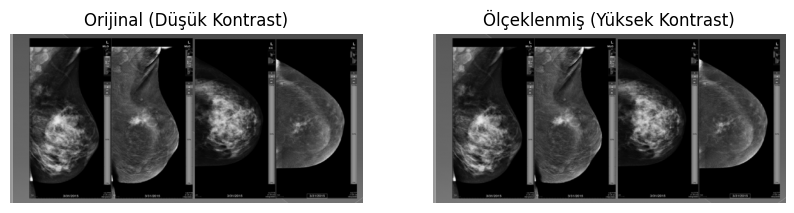

In [6]:
import cv2
import matplotlib.pyplot as plt

# Resimleri oku
orijinal = cv2.imread('resim.jpg', cv2.IMREAD_GRAYSCALE)
sonuc = cv2.imread('sonuc.jpg', cv2.IMREAD_GRAYSCALE)

# Yan yana çizdir
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(orijinal, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Orijinal (Düşük Kontrast)')
ax1.axis('off')

ax2.imshow(sonuc, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Ölçeklenmiş (Yüksek Kontrast)')
ax2.axis('off')

plt.show()